Fashion Image Classification Using ANNs and CNNs

Setup

In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install scikit-learn; numpy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import random
import time      
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)                # seeds Python, NumPy and TF together
tf.config.experimental.enable_op_determinism()   # deterministic TF operations

plt.rcParams["figure.dpi"] = 100
print("TensorFlow version:", tf.__version__)
print("NumPy version:     ", np.__version__)


TensorFlow version: 2.22.0-rc0
NumPy version:      2.4.6


1.DATA UNDERSTANDING & PREPARATION

1.1 LOADING THE DATASET

In [4]:
# Load Fashion-MNIST (downloads automatically on first run)
(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

print("Training images:", x_train_full.shape, "| dtype:", x_train_full.dtype)
print("Training labels:", y_train_full.shape)
print("Test images:    ", x_test.shape)
print("Test labels:    ", y_test.shape)
print("Pixel range:     min =", x_train_full.min(), ", max =", x_train_full.max())

Training images: (60000, 28, 28) | dtype: uint8
Training labels: (60000,)
Test images:     (10000, 28, 28)
Test labels:     (10000,)
Pixel range:     min = 0 , max = 255


1.2 CLASS LABELS

In [5]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
NUM_CLASSES = len(CLASS_NAMES)

# Count images per class to check whether the dataset is balanced
train_counts = np.bincount(y_train_full, minlength=NUM_CLASSES)
test_counts = np.bincount(y_test, minlength=NUM_CLASSES)
class_table = pd.DataFrame({"Label": range(NUM_CLASSES), "Class name": CLASS_NAMES,
                            "Train images": train_counts, "Test images": test_counts})
class_table

,Label,Class name,Train images,Test images
0,0,T-shirt/top,6000,1000
1,1,Trouser,6000,1000
2,2,Pullover,6000,1000
3,3,Dress,6000,1000
4,4,Coat,6000,1000
5,5,Sandal,6000,1000
6,6,Shirt,6000,1000
7,7,Sneaker,6000,1000
8,8,Bag,6000,1000
9,9,Ankle boot,6000,1000


### 1.2A Duplicate-image check

Before splitting the training data, exact duplicate images are checked using SHA-256 hashes.  
This checks for duplicates within the original training set, within the test set, and across the two sets.


In [6]:
import hashlib

def image_hashes(images):
    return [hashlib.sha256(img.tobytes()).hexdigest() for img in images]

train_hashes = image_hashes(x_train_full)
test_hashes = image_hashes(x_test)

train_hash_counts = pd.Series(train_hashes).value_counts()
test_hash_counts = pd.Series(test_hashes).value_counts()

duplicate_train_images = int((train_hash_counts > 1).sum())
duplicate_train_occurrences = int(train_hash_counts[train_hash_counts > 1].sum() - duplicate_train_images)

duplicate_test_images = int((test_hash_counts > 1).sum())
duplicate_test_occurrences = int(test_hash_counts[test_hash_counts > 1].sum() - duplicate_test_images)

cross_split_duplicates = len(set(train_hashes).intersection(test_hashes))

print("Exact duplicate image groups in original training set:", duplicate_train_images)
print("Additional duplicate occurrences in training set:", duplicate_train_occurrences)
print("Exact duplicate image groups in test set:", duplicate_test_images)
print("Additional duplicate occurrences in test set:", duplicate_test_occurrences)
print("Exact images shared between training and test sets:", cross_split_duplicates)

if duplicate_train_images == 0 and duplicate_test_images == 0 and cross_split_duplicates == 0:
    print("\nNo exact duplicate images were detected.")
else:
    print("\nExact duplicates were detected; investigate before final training.")


Exact duplicate image groups in original training set: 0
Additional duplicate occurrences in training set: 0
Exact duplicate image groups in test set: 0
Additional duplicate occurrences in test set: 0
Exact images shared between training and test sets: 0

No exact duplicate images were detected.


1.3 REPRESENTATIVE IMAGES

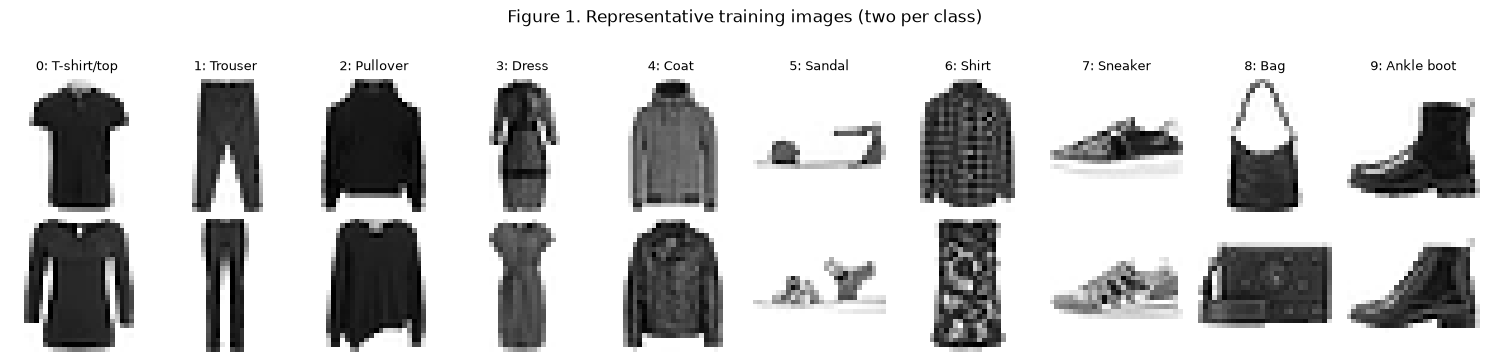

In [7]:
# Show two randomly chosen images for each of the 10 classes
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(15, 3.6))
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_train_full == c)[0], size=2, replace=False)
    for row in range(2):
        ax = axes[row, c]
        ax.imshow(x_train_full[idx[row]], cmap="gray_r")
        ax.axis("off")
        if row == 0:
            ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=9)
fig.suptitle("Figure 1. Representative training images (two per class)", y=1.02)
plt.tight_layout()
plt.show()

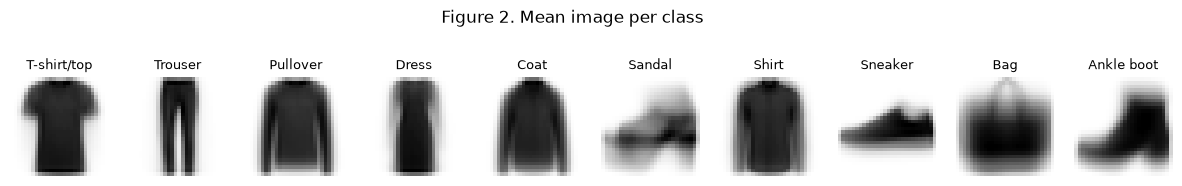

In [8]:
# Average ('mean') image per class: shows the typical shape the models must learn
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 2))
for c in range(NUM_CLASSES):
    axes[c].imshow(x_train_full[y_train_full == c].mean(axis=0), cmap="gray_r")
    axes[c].set_title(CLASS_NAMES[c], fontsize=9)
    axes[c].axis("off")
fig.suptitle("Figure 2. Mean image per class", y=1.08)
plt.show()

1.4 NOMALIZATION

In [9]:
# Scale pixel intensities from [0, 255] to [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(f"After normalisation: min = {x_train_full.min():.1f}, max = {x_train_full.max():.1f}, "
      f"mean = {x_train_full.mean():.3f}")

After normalisation: min = 0.0, max = 1.0, mean = 0.286


1.5 VALIDATION SPLIT

In [10]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.10,          # 6 000 validation images
    stratify=y_train_full,   # keep the 10 classes balanced in both parts
    random_state=SEED)

print("Training set:  ", x_train.shape, "| per class:", np.bincount(y_train))
print("Validation set:", x_val.shape, " | per class:", np.bincount(y_val))
print("Test set:      ", x_test.shape)

Training set:   (54000, 28, 28) | per class: [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400]
Validation set: (6000, 28, 28)  | per class: [600 600 600 600 600 600 600 600 600 600]
Test set:       (10000, 28, 28)


1.6 PREPARING THE INPUT SHAPE FOR CNN

In [11]:
# Add a channel axis: (N, 28, 28) > (N, 28, 28, 1)
x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]
print("CNN input shapes:", x_train_cnn.shape, x_val_cnn.shape, x_test_cnn.shape)

CNN input shapes: (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


2. SHARED TRAINING CONFIGURATION

In [12]:
BATCH_SIZE = 128
MAX_EPOCHS = 100
LEARNING_RATE = 1e-3

def compile_model(model):
    # Compile any model with the shared optimiser, loss and metric
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def make_callbacks(extra=None):
    # Early stopping shared by all models; extra callbacks can be added
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                         restore_best_weights=True, verbose=1)]
    return cbs + (extra or [])

def train_model(model, x_tr, y_tr, x_v, y_v, extra_callbacks=None):
    # Train a model on the shared split and return its history and training time
    keras.utils.set_random_seed(SEED)   # same shuffling order for every model
    start = time.time()
    history = model.fit(x_tr, y_tr,
                        validation_data=(x_v, y_v),
                        epochs=MAX_EPOCHS,
                        batch_size=BATCH_SIZE,
                        callbacks=make_callbacks(extra_callbacks),
                        verbose=2)       # one line per epoch
    elapsed = time.time() - start
    print(f"\nTraining time: {elapsed:.0f} s over {len(history.history['loss'])} epochs")
    return history, elapsed

def plot_history(history, title):
    # Plot training vs validation accuracy and loss side by side
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, h["accuracy"], "o-", ms=3, label="Training")
    ax1.plot(epochs, h["val_accuracy"], "s-", ms=3, label="Validation")
    ax1.set_title("Accuracy"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy")
    ax2.plot(epochs, h["loss"], "o-", ms=3, label="Training")
    ax2.plot(epochs, h["val_loss"], "s-", ms=3, label="Validation")
    ax2.set_title("Loss"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Cross-entropy loss")
    for ax in (ax1, ax2):
        ax.axvline(best, color="grey", ls="--", lw=1, label=f"Best epoch ({best})")
        ax.grid(alpha=0.3); ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def evaluate_model(model, x, y, name):
    # Evaluate on the test set; return predictions and a dictionary of metrics
    loss, acc = model.evaluate(x, y, verbose=0)
    probs = model.predict(x, verbose=0)
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y, y_pred, average="macro")
    metrics = {"Model": name, "Test accuracy": acc, "Test loss": loss,
               "Macro precision": p, "Macro recall": r, "Macro F1": f1,
               "Parameters": model.count_params()}
    print(f"{name}: test accuracy = {acc:.4f}, test loss = {loss:.4f}, macro F1 = {f1:.4f}")
    return y_pred, probs, metrics

results = {}   # stores metrics for the final comparison table

3. BASELINE ARTIFICIAL NEURAL NETWORK

3.1 ARCHITECTURE

In [13]:
def build_ann():
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(name="flatten"),                     # 28x28 -> 784
        layers.Dense(256, activation="relu", name="dense_1"),
        layers.Dropout(0.2, name="dropout_1"),
        layers.Dense(128, activation="relu", name="dense_2"),
        layers.Dropout(0.2, name="dropout_2"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="output"),
    ], name="Baseline_ANN")
    return compile_model(model)

ann = build_ann()
ann.summary()

Model: "Baseline_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

3.2 TRAINING

In [14]:
ann_history, ann_time = train_model(ann, x_train, y_train, x_val, y_val)

Epoch 1/100
422/422 - 116s - 275ms/step - accuracy: 0.7883 - loss: 0.5905 - val_accuracy: 0.8605 - val_loss: 0.3806
Epoch 2/100
422/422 - 48s - 114ms/step - accuracy: 0.8491 - loss: 0.4149 - val_accuracy: 0.8717 - val_loss: 0.3502
Epoch 3/100
422/422 - 61s - 144ms/step - accuracy: 0.8628 - loss: 0.3775 - val_accuracy: 0.8813 - val_loss: 0.3295
Epoch 4/100
422/422 - 84s - 199ms/step - accuracy: 0.8712 - loss: 0.3512 - val_accuracy: 0.8822 - val_loss: 0.3204
Epoch 5/100
422/422 - 40s - 96ms/step - accuracy: 0.8751 - loss: 0.3379 - val_accuracy: 0.8870 - val_loss: 0.3088
Epoch 6/100
422/422 - 19s - 46ms/step - accuracy: 0.8809 - loss: 0.3235 - val_accuracy: 0.8895 - val_loss: 0.3077
Epoch 7/100
422/422 - 16s - 39ms/step - accuracy: 0.8835 - loss: 0.3108 - val_accuracy: 0.8925 - val_loss: 0.2976
Epoch 8/100
422/422 - 16s - 37ms/step - accuracy: 0.8878 - loss: 0.3001 - val_accuracy: 0.8913 - val_loss: 0.3000
Epoch 9/100
422/422 - 16s - 38ms/step - accuracy: 0.8911 - loss: 0.2896 - val_accur

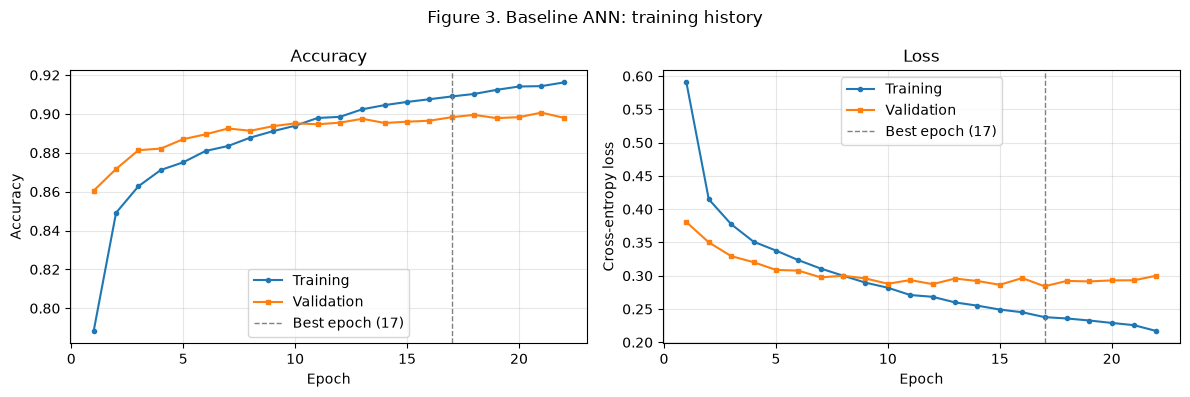

In [15]:
plot_history(ann_history, "Figure 3. Baseline ANN: training history")

3.3 TEST SET PERFORMANCE

In [16]:
ann_pred, ann_probs, results["Baseline ANN"] = evaluate_model(ann, x_test, y_test, "Baseline ANN")
results["Baseline ANN"]["Epochs trained"] = len(ann_history.history["loss"])
results["Baseline ANN"]["Training time (s)"] = ann_time

print("\nClassification report - Baseline ANN (test set)\n")
print(classification_report(y_test, ann_pred, target_names=CLASS_NAMES, digits=4))

Baseline ANN: test accuracy = 0.8855, test loss = 0.3316, macro F1 = 0.8854

Classification report - Baseline ANN (test set)

              precision    recall  f1-score   support

 T-shirt/top     0.8322    0.8580    0.8449      1000
     Trouser     0.9878    0.9710    0.9793      1000
    Pullover     0.7816    0.8090    0.7951      1000
       Dress     0.9063    0.8900    0.8981      1000
        Coat     0.7770    0.8190    0.7975      1000
      Sandal     0.9896    0.9500    0.9694      1000
       Shirt     0.7250    0.6670    0.6948      1000
     Sneaker     0.9093    0.9820    0.9442      1000
         Bag     0.9808    0.9730    0.9769      1000
  Ankle boot     0.9720    0.9360    0.9536      1000

    accuracy                         0.8855     10000
   macro avg     0.8862    0.8855    0.8854     10000
weighted avg     0.8862    0.8855    0.8854     10000



4. CONVOLUTIONAL NEURAL NETWORK

4.1 ARCHITECTURE

In [17]:
def build_cnn():
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv_1"),
        layers.MaxPooling2D((2, 2), name="pool_1"),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv_2"),
        layers.MaxPooling2D((2, 2), name="pool_2"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="output"),
    ], name="CNN")
    return compile_model(model)

cnn = build_cnn()
cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

4.2 TRAINING

In [18]:
cnn_history, cnn_time = train_model(cnn, x_train_cnn, y_train, x_val_cnn, y_val)

Epoch 1/100
422/422 - 145s - 343ms/step - accuracy: 0.8229 - loss: 0.4915 - val_accuracy: 0.8827 - val_loss: 0.3240
Epoch 2/100
422/422 - 189s - 447ms/step - accuracy: 0.8896 - loss: 0.3086 - val_accuracy: 0.8997 - val_loss: 0.2717
Epoch 3/100
422/422 - 135s - 321ms/step - accuracy: 0.9052 - loss: 0.2640 - val_accuracy: 0.9060 - val_loss: 0.2509
Epoch 4/100
422/422 - 156s - 369ms/step - accuracy: 0.9148 - loss: 0.2341 - val_accuracy: 0.9122 - val_loss: 0.2375
Epoch 5/100
422/422 - 130s - 308ms/step - accuracy: 0.9234 - loss: 0.2110 - val_accuracy: 0.9152 - val_loss: 0.2298
Epoch 6/100
422/422 - 144s - 342ms/step - accuracy: 0.9302 - loss: 0.1917 - val_accuracy: 0.9162 - val_loss: 0.2274
Epoch 7/100
422/422 - 135s - 321ms/step - accuracy: 0.9370 - loss: 0.1740 - val_accuracy: 0.9173 - val_loss: 0.2254
Epoch 8/100
422/422 - 131s - 312ms/step - accuracy: 0.9424 - loss: 0.1570 - val_accuracy: 0.9200 - val_loss: 0.2245
Epoch 9/100
422/422 - 145s - 344ms/step - accuracy: 0.9498 - loss: 0.140

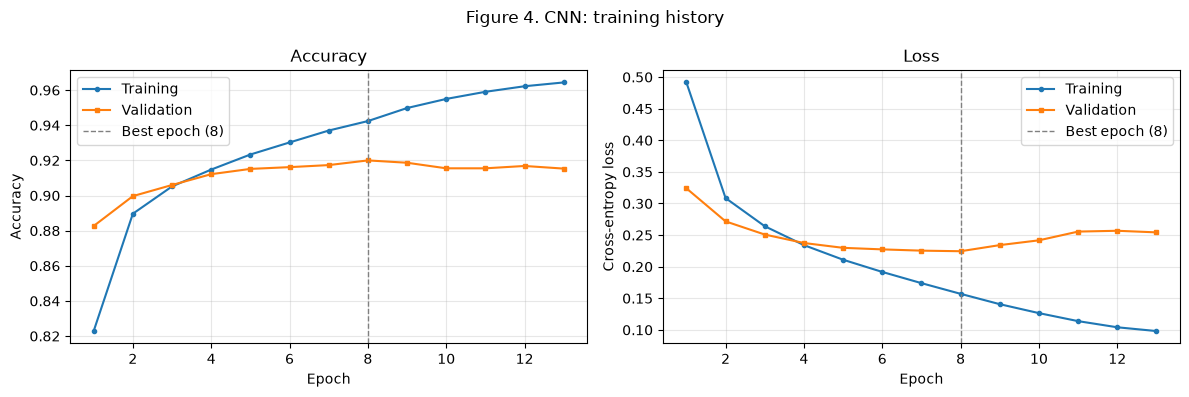

In [19]:
plot_history(cnn_history, "Figure 4. CNN: training history")

4.3 TEST SET PERFORMANCE

In [20]:
cnn_pred, cnn_probs, results["CNN"] = evaluate_model(cnn, x_test_cnn, y_test, "CNN")
results["CNN"]["Epochs trained"] = len(cnn_history.history["loss"])
results["CNN"]["Training time (s)"] = cnn_time

print("\nClassification report - CNN (test set)\n")
print(classification_report(y_test, cnn_pred, target_names=CLASS_NAMES, digits=4))

CNN: test accuracy = 0.9117, test loss = 0.2556, macro F1 = 0.9123

Classification report - CNN (test set)

              precision    recall  f1-score   support

 T-shirt/top     0.8686    0.8530    0.8607      1000
     Trouser     0.9698    0.9950    0.9822      1000
    Pullover     0.8648    0.8570    0.8609      1000
       Dress     0.9471    0.8780    0.9113      1000
        Coat     0.8606    0.8580    0.8593      1000
      Sandal     0.9850    0.9870    0.9860      1000
       Shirt     0.7237    0.7910    0.7559      1000
     Sneaker     0.9380    0.9840    0.9605      1000
         Bag     0.9908    0.9710    0.9808      1000
  Ankle boot     0.9895    0.9430    0.9657      1000

    accuracy                         0.9117     10000
   macro avg     0.9138    0.9117    0.9123     10000
weighted avg     0.9138    0.9117    0.9123     10000



5. IMPROVED CNN

5.1 IMPROVED 

In [21]:
def build_improved_cnn():
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        # Block 1: two 3x3 convolutions, batch norm, pooling, dropout
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv_1a"),
        layers.BatchNormalization(name="bn_1a"),
        layers.Activation("relu", name="relu_1a"),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv_1b"),
        layers.BatchNormalization(name="bn_1b"),
        layers.Activation("relu", name="relu_1b"),
        layers.MaxPooling2D((2, 2), name="pool_1"),
        layers.Dropout(0.25, name="dropout_1"),
        # Block 2: same pattern with 64 filters
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv_2a"),
        layers.BatchNormalization(name="bn_2a"),
        layers.Activation("relu", name="relu_2a"),
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv_2b"),
        layers.BatchNormalization(name="bn_2b"),
        layers.Activation("relu", name="relu_2b"),
        layers.MaxPooling2D((2, 2), name="pool_2"),
        layers.Dropout(0.25, name="dropout_2"),
        # Classifier hea\
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense"),
        layers.Dropout(0.5, name="dropout_3"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="output"),
    ], name="Improved_CNN")
    return compile_model(model)

improved_cnn = build_improved_cnn()
improved_cnn.summary()

Model: "Improved_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1a (Conv2D)                │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1a (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1a (Activation)            │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1b (Conv2D)                │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1b (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1b (Activation)            │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2a (Conv2D)                │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2a (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2a (Activation)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2b (Conv2D)                │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2b (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2b (Activation)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,394 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

5.2 TRAINING

In [22]:
# Extra callback for this model only: halve the learning rate when val_loss plateaus
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                              patience=2, min_lr=1e-5, verbose=1)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)
imp_history, imp_time = train_model(improved_cnn, x_train_cnn, y_train, x_val_cnn, y_val,
                                    extra_callbacks=[reduce_lr,early_stopping])

Epoch 1/100
422/422 - 1130s - 3s/step - accuracy: 0.7336 - loss: 0.7423 - val_accuracy: 0.7108 - val_loss: 0.7642 - learning_rate: 0.0010
Epoch 2/100
422/422 - 581s - 1s/step - accuracy: 0.8501 - loss: 0.4163 - val_accuracy: 0.9068 - val_loss: 0.2591 - learning_rate: 0.0010
Epoch 4/100
422/422 - 111s - 262ms/step - accuracy: 0.8645 - loss: 0.3764 - val_accuracy: 0.9112 - val_loss: 0.2439 - learning_rate: 0.0010
Epoch 5/100
422/422 - 112s - 265ms/step - accuracy: 0.8739 - loss: 0.3498 - val_accuracy: 0.9147 - val_loss: 0.2327 - learning_rate: 0.0010
Epoch 6/100
422/422 - 125s - 296ms/step - accuracy: 0.8827 - loss: 0.3305 - val_accuracy: 0.9118 - val_loss: 0.2348 - learning_rate: 0.0010
Epoch 7/100
422/422 - 124s - 293ms/step - accuracy: 0.8885 - loss: 0.3104 - val_accuracy: 0.9232 - val_loss: 0.2082 - learning_rate: 0.0010
Epoch 8/100
422/422 - 127s - 301ms/step - accuracy: 0.8930 - loss: 0.3002 - val_accuracy: 0.9252 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 9/100
422/422 - 127

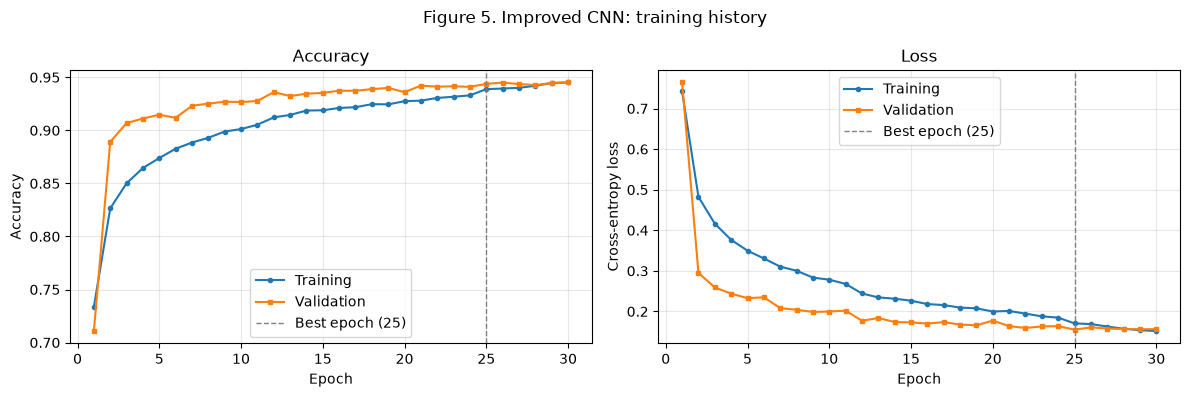

In [23]:
plot_history(imp_history, "Figure 5. Improved CNN: training history")

5.3 TEST SET PERFORMANCE

In [24]:
imp_pred, imp_probs, results["Improved CNN"] = evaluate_model(
    improved_cnn, x_test_cnn, y_test, "Improved CNN")
results["Improved CNN"]["Epochs trained"] = len(imp_history.history["loss"])
results["Improved CNN"]["Training time (s)"] = imp_time

print("\nClassification report - Improved CNN (test set)\n")
print(classification_report(y_test, imp_pred, target_names=CLASS_NAMES, digits=4))

Improved CNN: test accuracy = 0.9363, test loss = 0.1937, macro F1 = 0.9363

Classification report - Improved CNN (test set)

              precision    recall  f1-score   support

 T-shirt/top     0.8991    0.8730    0.8858      1000
     Trouser     0.9970    0.9870    0.9920      1000
    Pullover     0.9249    0.9110    0.9179      1000
       Dress     0.9194    0.9360    0.9277      1000
        Coat     0.8898    0.9290    0.9090      1000
      Sandal     0.9919    0.9850    0.9885      1000
       Shirt     0.8048    0.8000    0.8024      1000
     Sneaker     0.9628    0.9830    0.9728      1000
         Bag     0.9940    0.9910    0.9925      1000
  Ankle boot     0.9807    0.9680    0.9743      1000

    accuracy                         0.9363     10000
   macro avg     0.9364    0.9363    0.9363     10000
weighted avg     0.9364    0.9363    0.9363     10000



## 6. PERFORMANCE COMPARISON

The following table provides the required comparison of the baseline ANN, baseline CNN, and improved CNN on the unseen test set.


In [25]:
comparison_table = pd.DataFrame([
    results["Baseline ANN"],
    results["CNN"],
    results["Improved CNN"]
])

comparison_columns = [
    "Model", "Test accuracy", "Macro precision",
    "Macro recall", "Macro F1", "Parameters"
]

comparison_table[comparison_columns].style.format({
    "Test accuracy": "{:.4f}",
    "Macro precision": "{:.4f}",
    "Macro recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Parameters": "{:,}"
})


,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Parameters
0,Baseline ANN,0.8855,0.8862,0.8855,0.8854,"235,146"
1,CNN,0.9117,0.9138,0.9117,0.9123,"421,642"
2,Improved CNN,0.9363,0.9364,0.9363,0.9363,"468,394"


In [26]:
improvement_comparison = pd.DataFrame({
    "Metric": ["Test accuracy", "Macro precision", "Macro recall", "Macro F1"],
    "Baseline CNN": [
        results["CNN"]["Test accuracy"],
        results["CNN"]["Macro precision"],
        results["CNN"]["Macro recall"],
        results["CNN"]["Macro F1"]
    ],
    "Improved CNN": [
        results["Improved CNN"]["Test accuracy"],
        results["Improved CNN"]["Macro precision"],
        results["Improved CNN"]["Macro recall"],
        results["Improved CNN"]["Macro F1"]
    ]
})
improvement_comparison["Change"] = (
    improvement_comparison["Improved CNN"] -
    improvement_comparison["Baseline CNN"]
)
improvement_comparison.style.format({
    "Baseline CNN": "{:.4f}",
    "Improved CNN": "{:.4f}",
    "Change": "{:+.4f}"
})


,Metric,Baseline CNN,Improved CNN,Change
0,Test accuracy,0.9117,0.9363,+0.0246
1,Macro precision,0.9138,0.9364,+0.0226
2,Macro recall,0.9117,0.9363,+0.0246
3,Macro F1,0.9123,0.9363,+0.0240


## 7. CONFUSION MATRIX AND ERROR ANALYSIS

The final CNN is the improved CNN. The confusion matrix below identifies the classes most frequently confused by the final model.


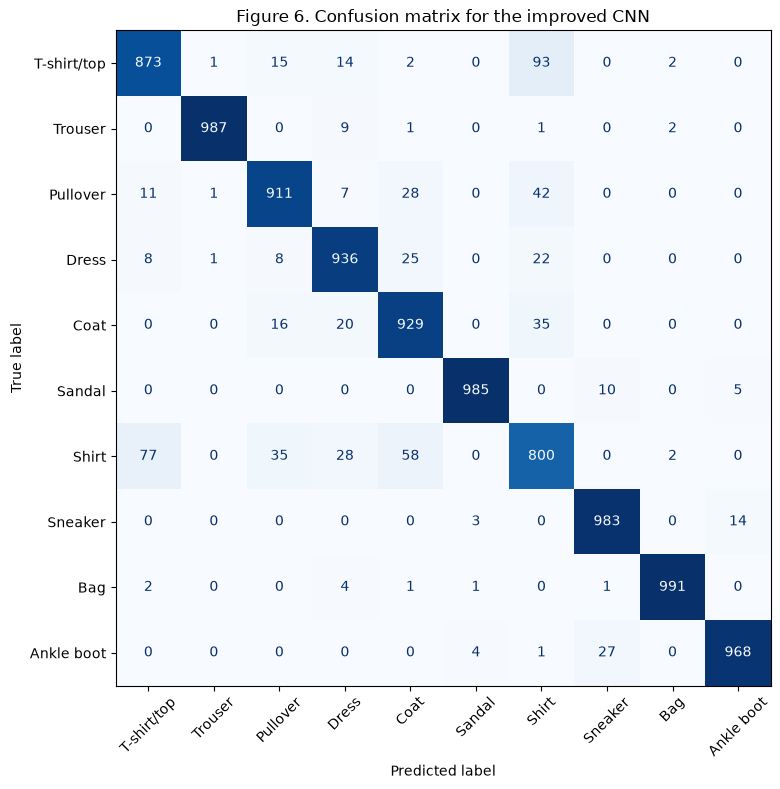

,True class,Predicted class,Misclassified images
0,T-shirt/top,Shirt,93
1,Shirt,T-shirt/top,77
2,Shirt,Coat,58
3,Pullover,Shirt,42
4,Shirt,Pullover,35
5,Coat,Shirt,35
6,Pullover,Coat,28
7,Shirt,Dress,28
8,Ankle boot,Sneaker,27
9,Dress,Coat,25


In [27]:
cm = confusion_matrix(y_test, imp_pred)

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Figure 6. Confusion matrix for the improved CNN")
plt.tight_layout()
plt.show()

# Identify the most common off-diagonal confusion pairs.
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = []
for true_idx, pred_idx in zip(*np.unravel_index(np.argsort(cm_off.ravel())[::-1], cm_off.shape)):
    count = cm_off[true_idx, pred_idx]
    if count == 0:
        break
    pairs.append({
        "True class": CLASS_NAMES[true_idx],
        "Predicted class": CLASS_NAMES[pred_idx],
        "Misclassified images": int(count)
    })
    if len(pairs) == 10:
        break

pd.DataFrame(pairs)


### Error analysis

Use the two highest-count off-diagonal pairs in the table above as the two commonly confused class pairs required by the brief. Explain each using the visual similarity of the clothing categories and the model's classification behaviour. For example, classes with similar silhouettes, short/long sleeves, collars, or overlapping shapes can be difficult to distinguish in 28×28 grayscale images. The explanation should be tied to the actual pairs identified by the confusion matrix rather than assumed in advance.


## 8. PREDICTION DEMONSTRATION

At least ten unseen test images are displayed with their true labels, predicted labels, and correctness.


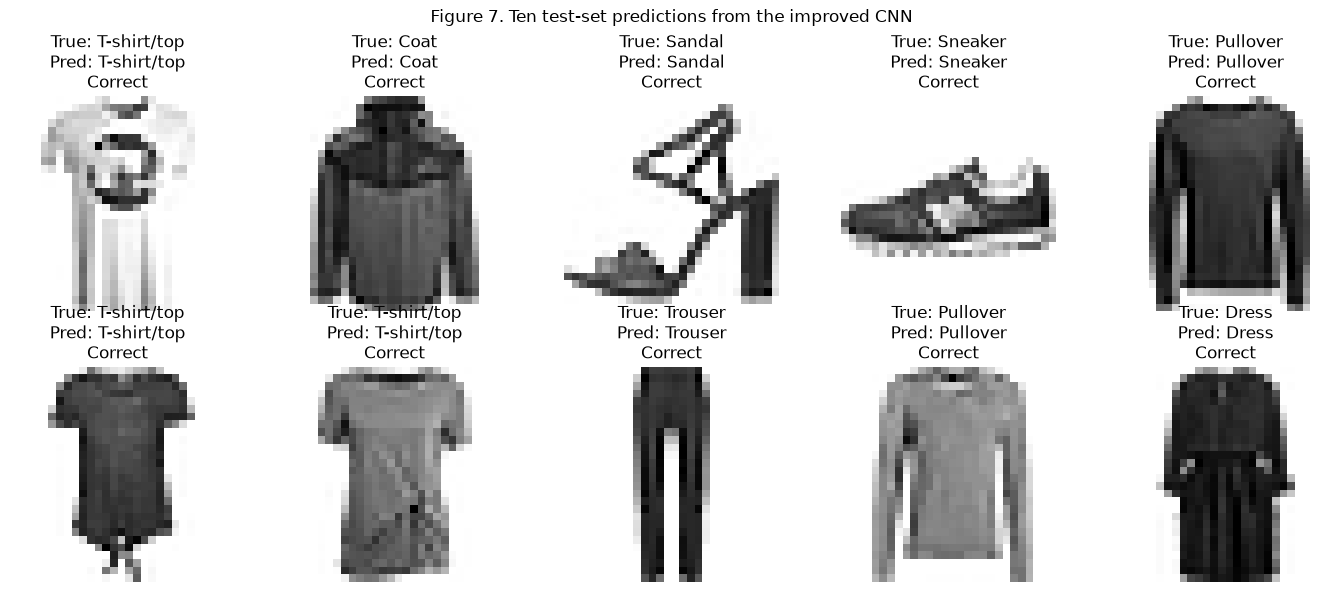

In [28]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(x_test_cnn), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.ravel(), sample_indices):
    ax.imshow(x_test[idx], cmap="gray_r")
    true_name = CLASS_NAMES[y_test[idx]]
    pred_name = CLASS_NAMES[imp_pred[idx]]
    correct = y_test[idx] == imp_pred[idx]
    ax.set_title(
        f"True: {true_name}\nPred: {pred_name}\n"
        f"{'Correct' if correct else 'Incorrect'}"
    )
    ax.axis("off")

fig.suptitle("Figure 7. Ten test-set predictions from the improved CNN")
plt.tight_layout()
plt.show()


## 9. FINAL INTERPRETATION

The improved CNN should be compared with the baseline CNN using the test-set results above. State whether the improvement increased or decreased performance, quantify the change, and identify the remaining error patterns from the confusion matrix. The unseen test set is used only for final evaluation; training and model-selection decisions use the training/validation split.
